# 4A. Buscador semántico híbrido y *re-ranking* con Transformers

**Autor:** David Segundo García · **Curso:** Recuperación de información 2026-2

Este notebook convierte el motor léxico de la actividad 2A (BM25 sobre 120 documentos en español) en un
buscador semántico de dos etapas:

1. **Recuperación densa.** Un *bi-encoder* codifica consulta y documentos en vectores; un índice HNSW
   (unidad 3) devuelve los 20 candidatos más cercanos por similitud coseno.
2. **Re-ranking.** Un *cross-encoder* lee cada par consulta–documento completo y reordena esos 20
   candidatos.

Se comparan **dos modelos de *embeddings*** y se evalúa todo contra BM25 con juicios de relevancia
graduados.

## Mapa del notebook

| Sección | Paso de la actividad | Contenido |
|---|---|---|
| 0 | — | Dependencias, semillas, dispositivo y versiones |
| 1 | — | Corpus de la unidad 2, línea base BM25 (port fiel de la 2A) y 20 consultas con juicios de relevancia |
| 2 | **Paso 1** | *Embeddings* con dos modelos: nombre, dimensión, parámetros, truncamiento |
| 3 | **Paso 2** | `buscar_semantico()`: Top-20 por coseno sobre un índice HNSW, verificado contra fuerza bruta |
| 4 | **Paso 3** | Pipeline de dos etapas con *cross-encoder* y medición de la latencia adicional |
| 5 | **Paso 4** | nDCG@5, MRR y recall@5 de 7 configuraciones (BM25, semántico, semántico + *re-ranking*, híbrido) |
| 6 | **Paso 5** | Interfaz `ipywidgets`: barra de búsqueda, botón y tablero lado a lado (semántico a la izquierda, BM25 a la derecha) |
| 7 | **Paso 6** | Casos en los que el buscador semántico recupera lo que BM25 ignoró por completo |
| 8 | — | Conclusiones (insumo del reporte en PDF) |

> **Reproducibilidad.** Todo corre en CPU con semillas fijas. La primera ejecución descarga de
> Hugging Face los cuatro modelos (~4 GB en total) a la caché local; las siguientes no necesitan red.
> Las tablas y figuras que usa el reporte se escriben en `results/` y `figures/`.

## 0. Dependencias y entorno

In [1]:
"""Buscador semántico híbrido y re-ranking con Transformers — actividad 4A."""

from __future__ import annotations

import os

# Deben fijarse antes de importar transformers: silencian barras de progreso que ensucian la salida
# guardada en el .ipynb y evitan el aviso de paralelismo de los tokenizadores.
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")

import html as _html
import json
import math
import platform
import random
import re
import statistics
import time
import unicodedata
import warnings
from collections import Counter
from dataclasses import dataclass
from pathlib import Path
from typing import Callable, Sequence

import hnswlib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sentence_transformers
import torch
import transformers
from sentence_transformers import CrossEncoder, SentenceTransformer

transformers.utils.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 170)

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

# CPU a propósito: los resultados son deterministas y las latencias comparables con las de BM25,
# que también corre en CPU. En Apple Silicon `mps` aceleraría la codificación, pero añade
# variación entre ejecuciones y un costo fijo de transferencia que distorsiona consultas pequeñas.
DEVICE = "cpu"

DIR_RESULTADOS = Path("results")
DIR_FIGURAS = Path("figures")
DIR_RESULTADOS.mkdir(exist_ok=True)
DIR_FIGURAS.mkdir(exist_ok=True)

print(f"Python {platform.python_version()} · {platform.machine()} · {platform.platform(terse=True)}")
print(f"torch {torch.__version__} (hilos CPU: {torch.get_num_threads()}) · transformers {transformers.__version__}")
print(f"sentence-transformers {sentence_transformers.__version__} · hnswlib {hnswlib.__version__ if hasattr(hnswlib, '__version__') else '0.8'}")
print(f"numpy {np.__version__} · pandas {pd.__version__} · dispositivo: {DEVICE}")

W1026 19:23:18.838000 14014 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Python 3.14.5 · arm64 · macOS-26.5.1
torch 2.14.1 (hilos CPU: 4) · transformers 5.21.0
sentence-transformers 6.2.0 · hnswlib 0.8
numpy 2.5.4 · pandas 3.1.0 · dispositivo: cpu


In [2]:
# ipywidgets solo se usa en la interfaz del paso 5; el resto del notebook funciona sin él.
try:
    import ipywidgets as widgets
    from IPython.display import HTML, display

    HAY_WIDGETS = True
    print(f"ipywidgets {widgets.__version__} disponible")
except ImportError:  # pragma: no cover - depende del entorno
    from IPython.display import HTML, display

    HAY_WIDGETS = False
    print("ipywidgets NO disponible -> pip install ipywidgets (el tablero estático sigue funcionando)")

ipywidgets 8.1.9 disponible


## 1. Corpus y línea base léxica (BM25)

Se reutiliza **el mismo corpus de la unidad 2**: 120 documentos en español, 10 por cada una de 12
temáticas. Su vocabulario se redactó a propósito con *automóvil*, *médico* y *computadora* y sin sus
sinónimos *coche*, *doctor* u *ordenador*, para exhibir el límite de la coincidencia exacta.

La línea base es el BM25 de la actividad 2A, portado sin cambios: mismo preprocesamiento (minúsculas,
tokenización, *stopwords*, *Snowball stemmer*, eliminación de tildes), mismo IDF de Lucene y mismos
parámetros $k_1 = 1.5$, $b = 0.75$. Una celda de control verifica que reproduce las puntuaciones
publicadas en la 2A.

In [3]:
def cargar_corpus() -> list[dict]:
    """Carga el corpus de la unidad 2.

    Busca ``corpus/corpus.json`` junto al notebook y, como respaldo, en la carpeta de la entrega 2A.

    Returns:
        Lista de documentos con las claves ``id``, ``titulo``, ``categoria`` y ``texto``.

    Raises:
        FileNotFoundError: Si no se encuentra el archivo en ninguna de las rutas candidatas.
    """
    for candidata in (Path("corpus/corpus.json"), Path("../Entrega_2A/corpus/corpus.json")):
        if candidata.exists():
            return json.loads(candidata.read_text(encoding="utf-8"))
    raise FileNotFoundError("No se encontró corpus/corpus.json")


CORPUS = cargar_corpus()
DOCS = {d["id"]: d for d in CORPUS}
IDS = [d["id"] for d in CORPUS]
# Texto que ven los tres modelos y BM25: título + cuerpo, igual que el índice de la 2A.
TEXTOS = [f"{d['titulo']}. {d['texto']}" for d in CORPUS]

df_corpus = pd.DataFrame(CORPUS)
df_corpus["palabras"] = [len(t.split()) for t in TEXTOS]
print(f"Documentos: {len(CORPUS)} · temáticas: {df_corpus['categoria'].nunique()}")
print(f"Palabras por documento: media {df_corpus['palabras'].mean():.1f}, "
      f"mín {df_corpus['palabras'].min()}, máx {df_corpus['palabras'].max()}")
print(df_corpus.groupby("categoria").size().rename("documentos").to_string())

Documentos: 120 · temáticas: 12
Palabras por documento: media 57.3, mín 45, máx 81
categoria
Arte y Música              10
Astronomía                 10
Ciberseguridad             10
Deportes                   10
Economía                   10
Gastronomía                10
Historia                   10
Inteligencia Artificial    10
Medio Ambiente             10
Salud                      10
Transporte                 10
Viajes y Geografía         10


In [4]:
# --- Preprocesamiento de la 2A (idéntico) -------------------------------------------------------
STOPWORDS_RESPALDO = {
    "a", "al", "algo", "algunas", "algunos", "ante", "antes", "aquel", "aquella", "aquello",
    "aqui", "aquí", "asi", "así", "aunque", "bajo", "bien", "cada", "casi", "como", "cómo",
    "con", "contra", "cual", "cuales", "cuando", "cuanto", "de", "del", "desde", "donde",
    "dos", "durante", "e", "el", "él", "ella", "ellas", "ellos", "en", "entre", "era", "eran",
    "eres", "es", "esa", "esas", "ese", "eso", "esos", "esta", "está", "están", "estas", "este",
    "esto", "estos", "estar", "fue", "fueron", "ha", "haber", "hacia", "han", "hasta", "hay",
    "incluso", "la", "las", "le", "les", "lo", "los", "mas", "más", "me", "mediante", "mi",
    "mientras", "mucho", "muchos", "muy", "ni", "no", "nos", "o", "otra", "otras", "otro",
    "otros", "para", "pero", "poco", "por", "porque", "pues", "que", "qué", "quien", "se",
    "sea", "sean", "segun", "según", "ser", "si", "sí", "sido", "siendo", "sin", "sobre",
    "solo", "sólo", "son", "su", "sus", "tambien", "también", "tan", "tanto", "te", "tiene",
    "tienen", "toda", "todas", "todo", "todos", "tras", "tu", "tus", "un", "una", "uno",
    "unos", "y", "ya", "yo",
    "estaba", "estaban", "estamos", "estan", "están", "estas", "estás", "esté", "estén",
    "estuvo", "fuera", "fueran", "fuese", "fui", "fuimos", "fuiste", "ha", "habia", "había",
    "habian", "habían", "habrá", "hace", "hacen", "hacer", "hacía", "hago", "han", "has",
    "hemos", "hizo", "hubo", "puede", "pueden", "pudo", "sera", "será", "seran", "serán",
    "tenemos", "tenga", "tengo", "tenia", "tenía", "tuvo", "va", "van", "vez", "veces",
}

try:
    import nltk
    from nltk.corpus import stopwords as _sw
    from nltk.stem import SnowballStemmer

    try:
        _palabras_nltk = _sw.words("spanish")
    except LookupError:
        nltk.download("stopwords", quiet=True)
        _palabras_nltk = _sw.words("spanish")
    STOPWORDS = set(_palabras_nltk) | STOPWORDS_RESPALDO
    STEM: Callable[[str], str] = SnowballStemmer("spanish").stem
    ORIGEN_PREPROCESAMIENTO = "nltk (stopwords + SnowballStemmer)"
except Exception:  # pragma: no cover - sin nltk el ranking difiere ligeramente del de la 2A
    STOPWORDS = STOPWORDS_RESPALDO
    STEM = lambda palabra: palabra  # noqa: E731
    ORIGEN_PREPROCESAMIENTO = "respaldo SIN stemming (instala nltk para reproducir la 2A)"

PATRON_TOKEN = re.compile(r"[a-záéíóúüñ0-9]+")


def quitar_acentos(texto: str) -> str:
    """Elimina las tildes conservando la ``ñ``."""
    protegido = texto.replace("ñ", "\0")
    descompuesto = unicodedata.normalize("NFD", protegido)
    sin_tildes = "".join(c for c in descompuesto if unicodedata.category(c) != "Mn")
    return unicodedata.normalize("NFC", sin_tildes).replace("\0", "ñ")


def preprocesar(texto: str) -> list[str]:
    """Minúsculas -> tokens -> sin tokens de 1 carácter -> sin stopwords -> raíz sin tildes."""
    tokens = PATRON_TOKEN.findall(texto.lower())
    return [quitar_acentos(STEM(t)) for t in tokens if len(t) > 1 and t not in STOPWORDS]


print(f"Preprocesamiento: {ORIGEN_PREPROCESAMIENTO} · {len(STOPWORDS)} stopwords")

Preprocesamiento: nltk (stopwords + SnowballStemmer) · 368 stopwords


In [5]:
class BM25:
    """BM25 sobre un índice invertido en memoria (versión compacta de la actividad 2A).

    Attributes:
        k1: Saturación de la frecuencia de término.
        b: Grado de normalización por longitud del documento.
        postings: Mapa ``término -> {doc_id: tf}``.
        longitudes: Número de términos de cada documento tras el preprocesamiento.
        avgdl: Longitud promedio de los documentos.
    """

    def __init__(self, ids: Sequence[str], textos: Sequence[str], k1: float = 1.5, b: float = 0.75) -> None:
        """Construye el índice invertido y precalcula el IDF de todo el vocabulario."""
        self.k1, self.b = k1, b
        self.postings: dict[str, dict[str, int]] = {}
        self.longitudes: dict[str, int] = {}
        for doc_id, texto in zip(ids, textos):
            tokens = preprocesar(texto)
            self.longitudes[doc_id] = len(tokens)
            for termino, tf in Counter(tokens).items():
                self.postings.setdefault(termino, {})[doc_id] = tf
        self.n_docs = len(ids)
        self.avgdl = sum(self.longitudes.values()) / self.n_docs
        self.idf = {
            t: math.log(1 + (self.n_docs - len(p) + 0.5) / (len(p) + 0.5)) for t, p in self.postings.items()
        }

    def df(self, termino: str) -> int:
        """Número de documentos que contienen el término."""
        return len(self.postings.get(termino, {}))

    def puntuar(self, consulta: str) -> dict[str, float]:
        """Puntúa todos los documentos que comparten al menos un término con la consulta.

        Returns:
            Mapa ``doc_id -> score``. Un documento ausente tiene score 0: BM25 no lo ve.
        """
        scores: dict[str, float] = {}
        for termino in preprocesar(consulta):
            for doc_id, tf in self.postings.get(termino, {}).items():
                norma = 1 - self.b + self.b * self.longitudes[doc_id] / self.avgdl
                scores[doc_id] = scores.get(doc_id, 0.0) + self.idf[termino] * tf * (self.k1 + 1) / (tf + self.k1 * norma)
        return scores

    def buscar(self, consulta: str, top_k: int = 20) -> list[dict]:
        """Devuelve los ``top_k`` documentos con score > 0, ordenados de mayor a menor."""
        scores = self.puntuar(consulta)
        orden = sorted(scores.items(), key=lambda par: (-par[1], par[0]))[:top_k]
        return [{"id": d, "score": s} for d, s in orden]


bm25 = BM25(IDS, TEXTOS)
print(f"BM25(k1={bm25.k1}, b={bm25.b}) · vocabulario {len(bm25.postings):,} raíces · avgdl {bm25.avgdl:.2f}")

# Control de regresión contra la 2A: allí 'coche eléctrico' daba 5.02 y 'automóvil eléctrico' 10.37
# en el primer resultado, y 'doctor' no devolvía nada.
for consulta in ("automóvil eléctrico", "coche eléctrico", "doctor"):
    r = bm25.buscar(consulta, top_k=1)
    print(f"  {consulta!r:24} -> " + (f"{r[0]['id']} score {r[0]['score']:.2f}" if r else "sin resultados"))

BM25(k1=1.5, b=0.75) · vocabulario 1,940 raíces · avgdl 32.50
  'automóvil eléctrico'    -> doc_090 score 10.37
  'coche eléctrico'        -> doc_090 score 5.02
  'doctor'                 -> sin resultados


### 1.1 Consultas de evaluación y juicios de relevancia (insumo de los pasos 2–4)

**20 consultas** escritas a mano, de dos tipos:

- **Léxicas (8)** — comparten vocabulario con el documento que buscan (*ransomware*, *nixtamalización*,
  *telescopio infrarrojo*). Es el terreno de BM25 y sirven de control: un buen sistema semántico no
  debería empeorarlas.
- **Paráfrasis (12)** — expresan la misma necesidad con sinónimos o con lenguaje cotidiano (*coche*
  por *automóvil*, *doctor* por *médico*, *por qué sube el precio de las cosas* por *inflación*).

**Juicios graduados** (*qrels*), asignados leyendo los 120 documentos con el criterio de la tabla y
**sin modificarlos después de ver los resultados** de la evaluación:

| Grado | Criterio |
|---|---|
| **2** · muy relevante | El documento responde directamente a la necesidad de información. |
| **1** · parcialmente relevante | Trata un aspecto relacionado o una parte de la necesidad. |
| 0 · no relevante | Cualquier otro documento (no se lista). |

Se definen aquí, junto al corpus, porque además de la evaluación del paso 4 las usan la verificación del índice (paso 2) y la medición de latencias (paso 3).

In [6]:
@dataclass(frozen=True)
class Consulta:
    """Consulta de evaluación con sus juicios de relevancia.

    Attributes:
        id: Identificador corto (``q01``…).
        tipo: ``"léxica"`` si comparte vocabulario con sus documentos, ``"paráfrasis"`` si no.
        texto: Consulta tal como la escribiría una persona.
        qrels: Mapa ``doc_id -> grado`` (2 muy relevante, 1 parcial). Lo no listado vale 0.
    """

    id: str
    tipo: str
    texto: str
    qrels: dict[str, int]


CONSULTAS: list[Consulta] = [
    # --- Léxicas: comparten términos con el documento buscado ------------------------------------
    Consulta("q01", "léxica", "agujero negro supermasivo en el centro de la galaxia",
             {"doc_011": 2, "doc_014": 1, "doc_015": 1, "doc_019": 1}),
    Consulta("q02", "léxica", "nixtamalización del maíz para tortillas", {"doc_031": 2}),
    Consulta("q03", "léxica", "ransomware respaldo y cifrado", {"doc_101": 2, "doc_109": 1}),
    Consulta("q04", "léxica", "energía solar fotovoltaica y almacenamiento en baterías",
             {"doc_061": 2, "doc_062": 1, "doc_091": 1}),
    Consulta("q05", "léxica", "inflación y tasa de interés del banco central",
             {"doc_050": 2, "doc_052": 1, "doc_056": 1}),
    Consulta("q06", "léxica", "telescopio espacial infrarrojo", {"doc_010": 2}),
    Consulta("q07", "léxica", "preparación para correr un maratón", {"doc_041": 2, "doc_028": 1}),
    Consulta("q08", "léxica", "autenticación multifactor y gestor de contraseñas",
             {"doc_102": 2, "doc_107": 2, "doc_100": 1}),
    # --- Paráfrasis: sinónimos o lenguaje cotidiano sin el vocabulario del corpus ------------------
    Consulta("q09", "paráfrasis", "coche eléctrico que se recarga en poco tiempo", {"doc_090": 2, "doc_091": 1}),
    Consulta("q10", "paráfrasis", "cita con el doctor por videollamada", {"doc_027": 2}),
    Consulta("q11", "paráfrasis", "ordenador que aprende a partir de ejemplos",
             {"doc_000": 2, "doc_001": 1, "doc_005": 1}),
    Consulta("q12", "paráfrasis", "vehículo de cero emisiones",
             {"doc_090": 2, "doc_091": 1, "doc_094": 1, "doc_097": 1}),
    Consulta("q13", "paráfrasis", "cómo evitar que me roben las cuentas en internet",
             {"doc_102": 2, "doc_107": 2, "doc_100": 2, "doc_105": 1}),
    Consulta("q14", "paráfrasis", "por qué sube el precio de las cosas",
             {"doc_050": 2, "doc_052": 1, "doc_053": 1, "doc_056": 1}),
    Consulta("q15", "paráfrasis", "pan apto para celíacos", {"doc_037": 2, "doc_030": 1}),
    Consulta("q16", "paráfrasis", "dormir poco afecta la concentración", {"doc_025": 2, "doc_023": 1}),
    Consulta("q17", "paráfrasis", "planetas parecidos a la Tierra donde podría haber vida",
             {"doc_013": 2, "doc_012": 1}),
    Consulta("q18", "paráfrasis", "el derrumbe del imperio de Roma", {"doc_072": 2}),
    Consulta("q19", "paráfrasis", "buscar textos por su significado y no por sus palabras",
             {"doc_007": 2, "doc_003": 1}),
    Consulta("q20", "paráfrasis", "cuidar el corazón", {"doc_026": 2, "doc_024": 1}),
]
QRELS = {c.texto: c.qrels for c in CONSULTAS}

assert all(d in DOCS for c in CONSULTAS for d in c.qrels), "qrel con un id inexistente"
tabla_qrels = pd.DataFrame([
    {"id": c.id, "tipo": c.tipo, "consulta": c.texto,
     "relevantes (grado)": ", ".join(f"{d}({g})" for d, g in c.qrels.items())}
    for c in CONSULTAS
])
tabla_qrels.to_csv(DIR_RESULTADOS / "juicios_relevancia.csv", index=False)
print(tabla_qrels.to_string(index=False))
print(f"\n{len(CONSULTAS)} consultas · {sum(len(c.qrels) for c in CONSULTAS)} juicios positivos · "
      f"{sum(g == 2 for c in CONSULTAS for g in c.qrels.values())} de grado 2")

 id       tipo                                                consulta                             relevantes (grado)
q01     léxica    agujero negro supermasivo en el centro de la galaxia doc_011(2), doc_014(1), doc_015(1), doc_019(1)
q02     léxica                 nixtamalización del maíz para tortillas                                     doc_031(2)
q03     léxica                           ransomware respaldo y cifrado                         doc_101(2), doc_109(1)
q04     léxica energía solar fotovoltaica y almacenamiento en baterías             doc_061(2), doc_062(1), doc_091(1)
q05     léxica           inflación y tasa de interés del banco central             doc_050(2), doc_052(1), doc_056(1)
q06     léxica                          telescopio espacial infrarrojo                                     doc_010(2)
q07     léxica                      preparación para correr un maratón                         doc_041(2), doc_028(1)
q08     léxica       autenticación multifactor y gestor 

## 2. Paso 1 — *Embeddings* densos con dos modelos pre-entrenados

Se comparan dos *bi-encoders* multilingües de la librería `sentence-transformers` (Hugging Face). Los dos
procesan español de forma nativa, pero difieren en tamaño, dimensión y objetivo de entrenamiento:

| | **A · MiniLM** | **B · E5** |
|---|---|---|
| Identificador | `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` | `intfloat/multilingual-e5-base` |
| Arquitectura | MiniLM de 12 capas, destilado de mpnet; *mean pooling* | XLM-RoBERTa base de 12 capas; *mean pooling* |
| Entrenamiento | Paráfrasis (destilación multilingüe, 50+ idiomas) | Contrastivo débil a gran escala + ajuste supervisado en recuperación (MS MARCO, NQ…) |
| Dimensión | 384 | 768 |
| Entrada | Texto tal cual | Prefijos obligatorios `query: ` / `passage: ` (asimétrico) |

La hipótesis a contrastar: **E5 fue entrenado para recuperar** (consulta corta → pasaje largo), mientras
que MiniLM fue entrenado para detectar paráfrasis (frase ↔ frase de longitud parecida). Se espera que E5
rinda mejor con consultas breves, a cambio del doble de dimensión y un modelo ~2.3× más grande.

Todos los vectores se **normalizan a norma 1**, de modo que el producto interno es exactamente la
similitud coseno.

In [7]:
@dataclass(frozen=True)
class ConfigModelo:
    """Ficha de un modelo de *embeddings*.

    Attributes:
        clave: Nombre corto usado en tablas y figuras.
        nombre_hf: Identificador del modelo en Hugging Face.
        prefijo_consulta: Texto que el modelo espera antes de cada consulta.
        prefijo_documento: Texto que el modelo espera antes de cada documento.
    """

    clave: str
    nombre_hf: str
    prefijo_consulta: str = ""
    prefijo_documento: str = ""


MODELOS_CONFIG = [
    ConfigModelo("MiniLM", "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"),
    # E5 es asimétrico: sin los prefijos su calidad cae de forma notable (documentado en la ficha del modelo).
    ConfigModelo("E5", "intfloat/multilingual-e5-base", "query: ", "passage: "),
]


class BuscadorDenso:
    """*Bi-encoder* + índice HNSW sobre el corpus.

    Attributes:
        config: Ficha del modelo.
        modelo: Instancia de ``SentenceTransformer``.
        embeddings: Matriz ``(N, d)`` de vectores unitarios ``float32`` del corpus.
        indice: Índice ``hnswlib`` con espacio coseno.
        segundos_codificacion: Tiempo de codificar el corpus completo.
    """

    def __init__(self, config: ConfigModelo, textos: Sequence[str]) -> None:
        """Carga el modelo y codifica el corpus (el índice se construye aparte, en el paso 2)."""
        self.config = config
        self.modelo = SentenceTransformer(config.nombre_hf, device=DEVICE)
        self.modelo.eval()
        inicio = time.perf_counter()
        self.embeddings = self.modelo.encode(
            [config.prefijo_documento + t for t in textos],
            batch_size=16,
            normalize_embeddings=True,
            convert_to_numpy=True,
            show_progress_bar=False,
        ).astype(np.float32)
        self.segundos_codificacion = time.perf_counter() - inicio
        self.indice: hnswlib.Index | None = None

    @property
    def dimension(self) -> int:
        """Dimensión de los vectores generados."""
        return int(self.modelo.get_embedding_dimension())

    def codificar_consulta(self, consulta: str) -> np.ndarray:
        """Vector unitario de la consulta, con el prefijo que el modelo espera."""
        return self.modelo.encode(
            self.config.prefijo_consulta + consulta,
            normalize_embeddings=True,
            convert_to_numpy=True,
            show_progress_bar=False,
        ).astype(np.float32)

    def ficha(self) -> dict:
        """Resumen documentado del modelo para la tabla del paso 1."""
        tokenizador = self.modelo.tokenizer
        longitudes = [len(tokenizador(self.config.prefijo_documento + t)["input_ids"]) for t in TEXTOS]
        max_seq = self.modelo.max_seq_length
        return {
            "modelo": self.config.clave,
            "identificador": self.config.nombre_hf,
            "dimension": self.dimension,
            "parametros_M": round(sum(p.numel() for p in self.modelo.parameters()) / 1e6, 1),
            "max_seq_length": max_seq,
            "tokens_doc_media": round(float(np.mean(longitudes)), 1),
            "tokens_doc_max": int(max(longitudes)),
            "docs_truncados": int(sum(n > max_seq for n in longitudes)),
            "codificar_corpus_s": round(self.segundos_codificacion, 2),
            "matriz_KB": round(self.embeddings.nbytes / 1024, 1),
        }


DENSOS: dict[str, BuscadorDenso] = {}
for config in MODELOS_CONFIG:
    DENSOS[config.clave] = BuscadorDenso(config, TEXTOS)
    print(f"{config.clave:6} -> embeddings {DENSOS[config.clave].embeddings.shape} "
          f"en {DENSOS[config.clave].segundos_codificacion:.1f} s")

MiniLM -> embeddings (120, 384) en 1.0 s


E5     -> embeddings (120, 768) en 3.2 s


In [8]:
fichas = pd.DataFrame([d.ficha() for d in DENSOS.values()])
fichas.to_csv(DIR_RESULTADOS / "modelos_embeddings.csv", index=False)
print(fichas.drop(columns="identificador").to_string(index=False))

for clave, densa in DENSOS.items():
    normas = np.linalg.norm(densa.embeddings, axis=1)
    print(f"\n{clave}: norma de los vectores en [{normas.min():.6f}, {normas.max():.6f}] -> coseno = producto interno")
truncados = fichas.set_index("modelo")["docs_truncados"]
print(
    f"\nLectura: MiniLM solo admite {DENSOS['MiniLM'].modelo.max_seq_length} tokens (E5, 512). Con documentos de "
    f"{fichas['tokens_doc_max'].max()} tokens como máximo, {'ningún documento se trunca' if truncados.sum() == 0 else f'{truncados.to_dict()} documentos se truncan'}: "
    "los dos modelos ven el texto completo y la comparación es justa. En un corpus de documentos "
    "largos habría que dividirlos en fragmentos (chunking) antes de codificar."
)

modelo  dimension  parametros_M  max_seq_length  tokens_doc_media  tokens_doc_max  docs_truncados  codificar_corpus_s  matriz_KB
MiniLM        384         117.7             128              86.0             108               0                0.96      180.0
    E5        768         278.0             512              88.0             110               0                3.18      360.0

MiniLM: norma de los vectores en [1.000000, 1.000000] -> coseno = producto interno

E5: norma de los vectores en [1.000000, 1.000000] -> coseno = producto interno

Lectura: MiniLM solo admite 128 tokens (E5, 512). Con documentos de 110 tokens como máximo, ningún documento se trunca: los dos modelos ven el texto completo y la comparación es justa. En un corpus de documentos largos habría que dividirlos en fragmentos (chunking) antes de codificar.


In [9]:
# Geometría del espacio: ¿cómo se reparten las similitudes entre documentos?
filas = []
categorias = np.array([d["categoria"] for d in CORPUS])
misma_categoria = categorias[:, None] == categorias[None, :]
fuera_diagonal = ~np.eye(len(CORPUS), dtype=bool)
for clave, densa in DENSOS.items():
    sim = densa.embeddings @ densa.embeddings.T
    intra = sim[misma_categoria & fuera_diagonal]
    inter = sim[~misma_categoria]
    filas.append({
        "modelo": clave,
        "coseno medio (misma temática)": round(float(intra.mean()), 3),
        "coseno medio (temáticas distintas)": round(float(inter.mean()), 3),
        "separación": round(float(intra.mean() - inter.mean()), 3),
        "rango total": f"[{sim[fuera_diagonal].min():.2f}, {sim[fuera_diagonal].max():.2f}]",
    })
print(pd.DataFrame(filas).to_string(index=False))
print(
    "\nLectura: E5 concentra todas las similitudes en una banda estrecha y alta (anisotropía). No es "
    "un defecto para ordenar —solo importa el orden relativo—, pero implica que un umbral absoluto de "
    "coseno (p. ej. 'descartar < 0.5') no es trasladable de un modelo a otro."
)

modelo  coseno medio (misma temática)  coseno medio (temáticas distintas)  separación   rango total
MiniLM                          0.412                               0.186       0.226 [-0.17, 0.80]
    E5                          0.799                               0.762       0.037  [0.69, 0.89]

Lectura: E5 concentra todas las similitudes en una banda estrecha y alta (anisotropía). No es un defecto para ordenar —solo importa el orden relativo—, pero implica que un umbral absoluto de coseno (p. ej. 'descartar < 0.5') no es trasladable de un modelo a otro.


## 3. Paso 2 — Recuperación Top-20 por similitud coseno con un índice HNSW

`buscar_semantico()` codifica la consulta con **el mismo modelo** que el corpus, consulta un índice
**HNSW** (`hnswlib`, el índice recomendado en la actividad 3A por su relación recall/latencia) y devuelve
los 20 documentos más similares con su coseno.

Configuración del índice: `space='cosine'`, `M=16`, `ef_construction=200`, `ef_search=64` (≥ k).
`hnswlib` devuelve la distancia $1 - \cos$, que se convierte de vuelta a similitud.

Con 120 documentos la fuerza bruta es igual de rápida; el índice se incluye porque es lo que permitiría
escalar el mismo código a millones de documentos (unidad 3). Por eso la celda siguiente **verifica que
HNSW devuelve exactamente el mismo Top-20 que la búsqueda exhaustiva**.

In [10]:
K_CANDIDATOS = 20


def construir_indice(densa: BuscadorDenso, m: int = 16, ef_construction: int = 200, ef_search: int = 64) -> None:
    """Construye el índice HNSW de un buscador denso.

    Args:
        densa: Buscador cuyos *embeddings* se indexan.
        m: Aristas por nodo del grafo HNSW.
        ef_construction: Tamaño de la lista dinámica durante la construcción.
        ef_search: Tamaño de la lista dinámica en consulta; debe ser >= ``K_CANDIDATOS``.
    """
    n, d = densa.embeddings.shape
    indice = hnswlib.Index(space="cosine", dim=d)
    indice.init_index(max_elements=n, ef_construction=ef_construction, M=m, random_seed=SEMILLA)
    indice.add_items(densa.embeddings, np.arange(n), num_threads=1)
    indice.set_ef(ef_search)
    densa.indice = indice


def buscar_semantico(consulta: str, modelo: str = "E5", k: int = K_CANDIDATOS, tiempos: dict | None = None) -> list[dict]:
    """Recupera los ``k`` documentos más similares a la consulta por similitud coseno.

    Args:
        consulta: Consulta en lenguaje natural.
        modelo: Clave del modelo de *embeddings* (``"MiniLM"`` o ``"E5"``).
        k: Número de candidatos a devolver.
        tiempos: Si se pasa un diccionario, se le añaden los segundos de ``codificar`` e ``indice``.

    Returns:
        Lista ordenada de ``{"id", "score"}``, donde ``score`` es el coseno consulta–documento.
    """
    densa = DENSOS[modelo]
    t0 = time.perf_counter()
    vector = densa.codificar_consulta(consulta)
    t1 = time.perf_counter()
    etiquetas, distancias = densa.indice.knn_query(vector, k=k, num_threads=1)
    t2 = time.perf_counter()
    if tiempos is not None:
        tiempos["codificar"] = t1 - t0
        tiempos["indice"] = t2 - t1
    return [{"id": IDS[i], "score": 1.0 - float(dist)} for i, dist in zip(etiquetas[0], distancias[0])]


def buscar_exhaustivo(consulta: str, modelo: str = "E5", k: int = K_CANDIDATOS) -> list[dict]:
    """Referencia exacta: coseno contra los N documentos con un producto matricial."""
    densa = DENSOS[modelo]
    sims = densa.embeddings @ densa.codificar_consulta(consulta)
    orden = np.argsort(-sims, kind="stable")[:k]
    return [{"id": IDS[i], "score": float(sims[i])} for i in orden]


for densa in DENSOS.values():
    construir_indice(densa)
print(f"Índices HNSW construidos: {', '.join(f'{c} ({d.indice.get_current_count()} vectores, dim {d.dimension})' for c, d in DENSOS.items())}")

Índices HNSW construidos: MiniLM (120 vectores, dim 384), E5 (120 vectores, dim 768)


In [11]:
# Demostración: la consulta que en la 2A no devolvía NINGÚN resultado.
CONSULTA_DEMO = "cita con el doctor por videollamada"
print(f"BM25 -> {bm25.buscar(CONSULTA_DEMO, top_k=3)}  (términos: {preprocesar(CONSULTA_DEMO)})\n")
for clave in DENSOS:
    print(f"Top-5 semántico con {clave}:")
    for pos, r in enumerate(buscar_semantico(CONSULTA_DEMO, clave)[:5], start=1):
        print(f"  {pos}. coseno {r['score']:.3f}  {r['id']}  {DOCS[r['id']]['titulo']}")
    print()

BM25 -> [{'id': 'doc_046', 'score': 3.800565002139685}, {'id': 'doc_003', 'score': 3.3870716976758644}]  (términos: ['cit', 'doctor', 'videollam'])

Top-5 semántico con MiniLM:
  1. coseno 0.561  doc_027  Telemedicina y consulta a distancia
  2. coseno 0.341  doc_084  Fotografía documental
  3. coseno 0.311  doc_022  Resistencia a los antibióticos
  4. coseno 0.307  doc_020  Prevención de la diabetes tipo 2
  5. coseno 0.297  doc_026  Enfermedades cardiovasculares

Top-5 semántico con E5:
  1. coseno 0.865  doc_027  Telemedicina y consulta a distancia
  2. coseno 0.806  doc_006  Visión por computadora
  3. coseno 0.797  doc_020  Prevención de la diabetes tipo 2
  4. coseno 0.792  doc_047  Lesiones deportivas y rehabilitación
  5. coseno 0.791  doc_023  Salud mental y ansiedad



In [12]:
# Verificación del paso 2: HNSW contra fuerza bruta en las 20 consultas y los dos modelos.
filas = []
for clave in DENSOS:
    for c in CONSULTAS:
        aprox = buscar_semantico(c.texto, clave)
        exacto = buscar_exhaustivo(c.texto, clave)
        filas.append({
            "modelo": clave,
            "recall@20": len({r["id"] for r in aprox} & {r["id"] for r in exacto}) / K_CANDIDATOS,
            "mismo_orden": [r["id"] for r in aprox] == [r["id"] for r in exacto],
            "max_dif_coseno": max(abs(a["score"] - e["score"]) for a, e in zip(aprox, exacto)),
        })
verif = pd.DataFrame(filas).groupby("modelo").agg(
    recall_20_medio=("recall@20", "mean"),
    consultas_mismo_orden=("mismo_orden", "sum"),
    max_dif_coseno=("max_dif_coseno", "max"),
)
print(verif.to_string())
print("\nHNSW reproduce exactamente el Top-20 de la búsqueda exhaustiva: la primera etapa no pierde "
      "ningún candidato por usar un índice aproximado.")

        recall_20_medio  consultas_mismo_orden  max_dif_coseno
modelo                                                        
E5                  1.0                     20    1.192093e-06
MiniLM              1.0                     20    6.556511e-07

HNSW reproduce exactamente el Top-20 de la búsqueda exhaustiva: la primera etapa no pierde ningún candidato por usar un índice aproximado.


## 4. Paso 3 — Pipeline de dos etapas con *cross-encoder*

**Por qué dos etapas.** El *bi-encoder* codifica consulta y documento por separado: los vectores del corpus
se precalculan una sola vez y la búsqueda cuesta un producto interno. Es rápido pero "comprime" cada
documento en un único vector sin ver la consulta. El ***cross-encoder*** concatena
`[CLS] consulta [SEP] documento` y deja que la atención cruce cada palabra de la consulta con cada
palabra del documento; es mucho más preciso, pero cuesta una pasada completa del Transformer **por cada
par**, así que no puede aplicarse a todo el corpus. La solución estándar es combinarlos:

```
consulta ──► bi-encoder ──► HNSW: Top-20 por coseno ──► cross-encoder: 20 pares ──► orden definitivo
               (rápido, recall)                                (lento, precisión)
```

**Dos modelos de *re-ranking*** multilingües, de tamaños muy distintos:

| | **mMARCO** (ligero) | **BGE** (grande) |
|---|---|---|
| Identificador | `cross-encoder/mmarco-mMiniLMv2-L12-H384-v1` | `BAAI/bge-reranker-v2-m3` |
| Base | MiniLM multilingüe, 12 capas, 384 de ancho | XLM-RoBERTa *large* (BGE-M3), 24 capas, 1024 de ancho |
| Entrenamiento | mMARCO: MS MARCO traducido a 14 idiomas | Datos de *ranking* multilingües (BAAI) |

mMARCO devuelve un *logit* sin acotar y BGE una probabilidad en [0, 1] (sigmoide de su *logit*); en ambos
solo importa el orden que inducen sobre los candidatos.

> **Transparencia metodológica.** El diseño original usaba solo mMARCO. Al evaluarlo (sección 5)
> resultó que **empeoraba** el orden de E5, así que se añadió BGE para comprobar si el problema era la
> arquitectura de dos etapas o la capacidad del *re-ranker*. BGE se eligió **después** de ver los
> resultados de mMARCO sobre estas mismas 20 consultas; con un conjunto tan pequeño, esa elección no es
> una validación independiente, y así se reporta.

In [13]:
@dataclass(frozen=True)
class ConfigReranker:
    """Ficha de un *cross-encoder*.

    Attributes:
        clave: Nombre corto usado en tablas y figuras.
        nombre_hf: Identificador en Hugging Face.
    """

    clave: str
    nombre_hf: str


RERANKERS_CONFIG = [
    ConfigReranker("mMARCO", "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1"),
    ConfigReranker("BGE", "BAAI/bge-reranker-v2-m3"),
]
RERANKERS: dict[str, CrossEncoder] = {}
filas = []
for config in RERANKERS_CONFIG:
    RERANKERS[config.clave] = CrossEncoder(config.nombre_hf, device=DEVICE, max_length=512)
    filas.append({
        "re-ranker": config.clave,
        "identificador": config.nombre_hf,
        "parametros_M": round(sum(p.numel() for p in RERANKERS[config.clave].model.parameters()) / 1e6, 1),
        "max_length": 512,
    })
fichas_rr = pd.DataFrame(filas)
fichas_rr.to_csv(DIR_RESULTADOS / "modelos_reranking.csv", index=False)
print(fichas_rr.to_string(index=False))

POSICION = {doc_id: i for i, doc_id in enumerate(IDS)}


def reranquear(consulta: str, candidatos: list[dict], reranker: str = "BGE",
               tiempos: dict | None = None) -> list[dict]:
    """Reordena los candidatos con un *cross-encoder*.

    Args:
        consulta: Consulta en lenguaje natural.
        candidatos: Lista de ``{"id", "score"}`` de la primera etapa.
        reranker: Clave del *cross-encoder* (``"mMARCO"`` o ``"BGE"``).
        tiempos: Si se pasa, se le añade el tiempo de ``reranking`` en segundos.

    Returns:
        Nueva lista con ``score_ce`` (puntuación del cross-encoder), ``score`` original y ``rank_inicial``,
        ordenada por ``score_ce`` descendente (los empates conservan el orden de la primera etapa).
    """
    t0 = time.perf_counter()
    pares = [(consulta, TEXTOS[POSICION[c["id"]]]) for c in candidatos]
    logits = RERANKERS[reranker].predict(pares, batch_size=32, show_progress_bar=False) if pares else []
    if tiempos is not None:
        tiempos["reranking"] = time.perf_counter() - t0
    reordenados = [
        {**c, "score_ce": float(s), "rank_inicial": i + 1} for i, (c, s) in enumerate(zip(candidatos, logits))
    ]
    reordenados.sort(key=lambda r: (-r["score_ce"], r["rank_inicial"]))
    return reordenados


def buscar_con_reranking(consulta: str, modelo: str = "E5", reranker: str = "BGE",
                         k_candidatos: int = K_CANDIDATOS, tiempos: dict | None = None) -> list[dict]:
    """Pipeline completo: Top-``k_candidatos`` por coseno y orden final del *cross-encoder*."""
    return reranquear(consulta, buscar_semantico(consulta, modelo, k_candidatos, tiempos), reranker, tiempos)


candidatos_demo = buscar_semantico("vehículo de cero emisiones", "E5")
for clave_rr in RERANKERS:
    print(f"\n'vehículo de cero emisiones' · E5 + {clave_rr} (posición por coseno -> posición final):")
    for pos, r in enumerate(reranquear("vehículo de cero emisiones", candidatos_demo, clave_rr)[:5], start=1):
        print(f"  {pos}. (era #{r['rank_inicial']:>2}, coseno {r['score']:.3f}) CE {r['score_ce']:+6.2f}  {DOCS[r['id']]['titulo']}")
print("\nLos dos re-rankers reciben exactamente los mismos 20 candidatos; solo cambia el orden final.")

re-ranker                              identificador  parametros_M  max_length
   mMARCO cross-encoder/mmarco-mMiniLMv2-L12-H384-v1         117.6         512
      BGE                    BAAI/bge-reranker-v2-m3         567.8         512

'vehículo de cero emisiones' · E5 + mMARCO (posición por coseno -> posición final):


  1. (era #11, coseno 0.781) CE  -2.96  Trenes de alta velocidad
  2. (era # 1, coseno 0.819) CE  -3.70  Aviación y combustibles sostenibles
  3. (era # 6, coseno 0.787) CE  -3.99  Cohetes reutilizables
  4. (era # 2, coseno 0.816) CE  -4.28  Automóviles eléctricos y autonomía
  5. (era # 5, coseno 0.789) CE  -4.40  Baterías de estado sólido

'vehículo de cero emisiones' · E5 + BGE (posición por coseno -> posición final):


  1. (era # 2, coseno 0.816) CE  +0.05  Automóviles eléctricos y autonomía
  2. (era #11, coseno 0.781) CE  +0.01  Trenes de alta velocidad
  3. (era # 1, coseno 0.819) CE  +0.01  Aviación y combustibles sostenibles
  4. (era # 5, coseno 0.789) CE  +0.01  Baterías de estado sólido
  5. (era # 8, coseno 0.787) CE  +0.00  Motores de combustión interna

Los dos re-rankers reciben exactamente los mismos 20 candidatos; solo cambia el orden final.


### 4.1 Latencia adicional del *re-ranking*

Protocolo: las 20 consultas de evaluación (sección 1.1) × 5 repeticiones, tras 3 consultas de
calentamiento, en **CPU** (4 hilos de torch) y con el *cross-encoder* procesando los 20 pares en un único
lote. Cada etapa se cronometra por separado con `time.perf_counter()`:

- **codificar** — pasar la consulta por el *bi-encoder*.
- **índice** — búsqueda HNSW del Top-20 (o, en BM25, el ranking completo).
- ***re-ranking*** — 20 pares consulta–documento por el *cross-encoder*.

Ambos *re-rankers* reordenan **la misma** lista de candidatos de cada repetición, así que la diferencia
entre ellos es solo el costo del modelo. Se reportan mediana y percentil 95 (p95), más robustos que la
media frente a pausas del sistema operativo.

In [14]:
def medir_latencias(repeticiones: int = 5, calentamiento: int = 3) -> pd.DataFrame:
    """Cronometra cada etapa de todos los pipelines sobre las consultas de evaluación.

    Args:
        repeticiones: Veces que se ejecuta cada consulta.
        calentamiento: Consultas iniciales descartadas (carga de pesos en caché, inicialización de torch).

    Returns:
        ``DataFrame`` con una fila por (pipeline, consulta, repetición) y los milisegundos de cada etapa.
    """
    for c in CONSULTAS[:calentamiento]:
        bm25.buscar(c.texto)
        for clave in DENSOS:
            for clave_rr in RERANKERS:
                buscar_con_reranking(c.texto, clave, clave_rr)

    filas = []
    for rep in range(repeticiones):
        for c in CONSULTAS:
            t0 = time.perf_counter()
            bm25.buscar(c.texto, top_k=K_CANDIDATOS)
            filas.append({"pipeline": "BM25", "consulta": c.id, "rep": rep,
                          "codificar": 0.0, "indice": time.perf_counter() - t0, "reranking": 0.0})
            for clave in DENSOS:
                base: dict[str, float] = {}
                candidatos = buscar_semantico(c.texto, clave, tiempos=base)
                filas.append({"pipeline": clave, "consulta": c.id, "rep": rep, **base, "reranking": 0.0})
                for clave_rr in RERANKERS:
                    etapa: dict[str, float] = {}
                    reranquear(c.texto, candidatos, clave_rr, etapa)
                    filas.append({"pipeline": f"{clave} + {clave_rr}", "consulta": c.id, "rep": rep, **base, **etapa})
    datos = pd.DataFrame(filas)
    datos[["codificar", "indice", "reranking"]] *= 1000  # a milisegundos
    datos["solo_coseno"] = datos["codificar"] + datos["indice"]
    datos["total"] = datos["solo_coseno"] + datos["reranking"]
    return datos


latencias = medir_latencias()
latencias.to_csv(DIR_RESULTADOS / "latencias_crudas.csv", index=False)


def p95(serie: pd.Series) -> float:
    """Percentil 95."""
    return float(np.percentile(serie, 95))


ORDEN_PIPELINES = ["BM25", "MiniLM", "E5", "MiniLM + mMARCO", "E5 + mMARCO", "MiniLM + BGE", "E5 + BGE"]
resumen_lat = []
for pipeline in ORDEN_PIPELINES:
    g = latencias[latencias["pipeline"] == pipeline]
    fila = {"pipeline": pipeline}
    for etapa in ("codificar", "indice", "reranking", "solo_coseno", "total"):
        fila[f"{etapa}_mediana_ms"] = round(float(g[etapa].median()), 3)
        fila[f"{etapa}_p95_ms"] = round(p95(g[etapa]), 3)
    resumen_lat.append(fila)
resumen_lat = pd.DataFrame(resumen_lat).set_index("pipeline")
for clave in DENSOS:
    for clave_rr in RERANKERS:
        nombre = f"{clave} + {clave_rr}"
        resumen_lat.loc[nombre, "sobrecosto_x"] = round(
            resumen_lat.loc[nombre, "total_mediana_ms"] / resumen_lat.loc[clave, "total_mediana_ms"], 1)
resumen_lat.to_csv(DIR_RESULTADOS / "latencias_resumen.csv")

vista = pd.DataFrame({
    "codificar": resumen_lat["codificar_mediana_ms"],
    "índice/BM25": resumen_lat["indice_mediana_ms"],
    "re-ranking": resumen_lat["reranking_mediana_ms"],
    "total": resumen_lat["total_mediana_ms"],
    "total p95": resumen_lat["total_p95_ms"],
    "× vs. solo coseno": resumen_lat["sobrecosto_x"].fillna("—"),
})
print(f"Latencia en ms (mediana) sobre {latencias['consulta'].nunique()} consultas × {latencias['rep'].nunique()} repeticiones:\n")
print(vista.to_string())
for clave in DENSOS:
    for clave_rr in RERANKERS:
        f = resumen_lat.loc[f"{clave} + {clave_rr}"]
        print(f"\n{clave} + {clave_rr}: el re-ranking añade {f['reranking_mediana_ms']:.1f} ms a los "
              f"{resumen_lat.loc[clave, 'total_mediana_ms']:.1f} ms de la recuperación por coseno "
              f"({f['sobrecosto_x']:.1f}× más lento; p95 total {f['total_p95_ms']:.1f} ms).")

Latencia en ms (mediana) sobre 20 consultas × 5 repeticiones:

                 codificar  índice/BM25  re-ranking     total  total p95 × vs. solo coseno
pipeline                                                                                  
BM25                 0.000        0.078       0.000     0.078      0.165                 —
MiniLM               8.549        0.077       0.000     8.622     14.573                 —
E5                  20.080        0.129       0.000    20.214     32.434                 —
MiniLM + mMARCO      8.549        0.077     179.063   189.788    221.463              22.0
E5 + mMARCO         20.080        0.129     173.107   195.660    227.410               9.7
MiniLM + BGE         8.549        0.077    1727.756  1739.998   2039.120             201.8
E5 + BGE            20.080        0.129    1659.521  1679.057   1945.617              83.1

MiniLM + mMARCO: el re-ranking añade 179.1 ms a los 8.6 ms de la recuperación por coseno (22.0× más lento; p95 total 

/var/folders/_4/dm6n8zpj3y9b1n6s69y1mjm80000gn/T/ipykernel_14014/146515239.py:71: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  "× vs. solo coseno": resumen_lat["sobrecosto_x"].fillna("—"),


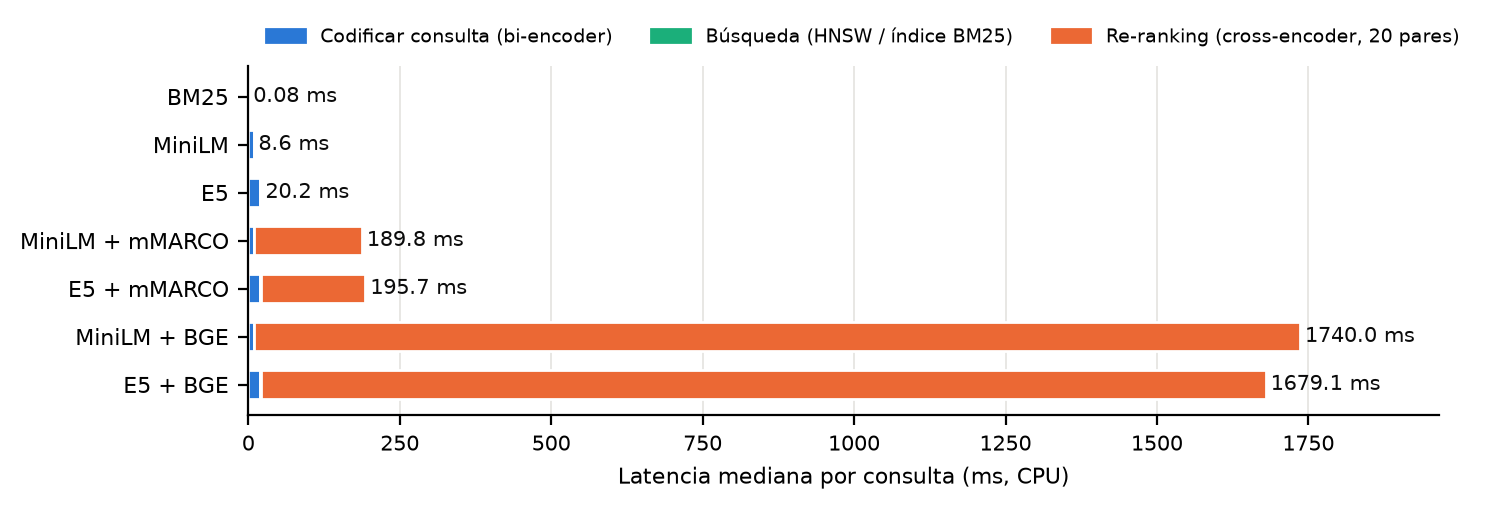

In [15]:
# Figura de latencias para el reporte: barras horizontales apiladas por etapa (mediana).
COLOR_ETAPA = {"codificar": "#2a78d6", "indice": "#1baf7a", "reranking": "#eb6834"}
ETIQUETA_ETAPA = {"codificar": "Codificar consulta (bi-encoder)", "indice": "Búsqueda (HNSW / índice BM25)",
                  "reranking": "Re-ranking (cross-encoder, 20 pares)"}
fig, ax = plt.subplots(figsize=(7.6, 2.7), dpi=200)
for y, pipeline in enumerate(ORDEN_PIPELINES):
    f = resumen_lat.loc[pipeline]
    izquierda = 0.0
    for etapa in ("codificar", "indice", "reranking"):
        ancho = f[f"{etapa}_mediana_ms"]
        if ancho <= 0:
            continue
        ax.barh(y, ancho, left=izquierda, color=COLOR_ETAPA[etapa], height=0.62, edgecolor="white", linewidth=1.0)
        izquierda += ancho
    total = f["total_mediana_ms"]  # mediana del total, no la suma de medianas por etapa
    texto = f"{total:.1f} ms" if total >= 1 else f"{total:.2f} ms"
    ax.text(izquierda + 8, y, texto, va="center", ha="left", fontsize=7.5, color="#0b0b0b")
ax.set_yticks(range(len(ORDEN_PIPELINES)), ORDEN_PIPELINES, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Latencia mediana por consulta (ms, CPU)", fontsize=8)
ax.tick_params(axis="x", labelsize=7.5)
ax.set_xlim(0, resumen_lat["total_mediana_ms"].max() * 1.13)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.grid(axis="x", color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
# Leyenda explícita en el orden de las etapas (la búsqueda dura < 0.1 ms y su segmento no se aprecia).
ax.legend([plt.Rectangle((0, 0), 1, 1, color=COLOR_ETAPA[e]) for e in ETIQUETA_ETAPA], ETIQUETA_ETAPA.values(),
          fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(0, 1.16), ncol=3)
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "latencias.png", bbox_inches="tight")
plt.show()

## 5. Paso 4 — Evaluación cuantitativa

### 5.1 Métricas (corte en 5, el tamaño de una primera página de resultados)

- **nDCG@5** (métrica principal) — usa el grado: premia colocar los documentos de grado 2 arriba.
  $\text{DCG@5} = \sum_{i=1}^{5} \frac{2^{rel_i}-1}{\log_2(i+1)}$, normalizado por el DCG del orden ideal.
- **MRR** — inverso de la posición del primer documento relevante (grado ≥ 1) en el Top-20.
- **recall@5** — fracción de los documentos relevantes (grado ≥ 1) que aparecen en el Top-5.
- **recall@20** (diagnóstico) — lo mismo sobre los 20 candidatos: es el **techo** del *re-ranking*, que
  solo puede reordenar lo que la primera etapa le entrega.

### 5.2 Las nueve configuraciones evaluadas

| Configuración | Primera etapa | Segunda etapa |
|---|---|---|
| **BM25** | BM25 de la unidad 2 | — |
| **MiniLM** / **E5** | Coseno Top-20 (HNSW) | — |
| **MiniLM + mMARCO** / **E5 + mMARCO** | Coseno Top-20 (HNSW) | *Cross-encoder* ligero sobre los 20 |
| **MiniLM + BGE** / **E5 + BGE** | Coseno Top-20 (HNSW) | *Cross-encoder* grande sobre los 20 |
| **Híbrido RRF** | Fusión BM25 + E5 por *Reciprocal Rank Fusion* | — |
| **Híbrido RRF + BGE** | Fusión BM25 + E5 | *Cross-encoder* grande sobre los 20 primeros de la fusión |

Las siete primeras filas cubren lo que pide la actividad (BM25, semántico y semántico + *re-ranking*)
con los dos modelos de *embeddings* y los dos *re-rankers*. Las dos híbridas responden al título de la actividad: **RRF** combina los rankings sin
necesidad de calibrar escalas de puntuación incompatibles (BM25 no está acotado; el coseno sí):
$\text{RRF}(d) = \sum_{s \in \{\text{BM25}, \text{E5}\}} \frac{1}{60 + \text{rank}_s(d)}$,
con $k=60$, el valor del artículo original (Cormack et al., 2009).

In [16]:
K_RRF = 60


def fusion_rrf(*rankings: list[dict], k: int = K_RRF, top_k: int = K_CANDIDATOS) -> list[dict]:
    """Fusiona rankings por *Reciprocal Rank Fusion*.

    Args:
        rankings: Listas ordenadas de ``{"id", ...}``.
        k: Constante de suavizado; amortigua la ventaja de las primeras posiciones.
        top_k: Longitud de la lista fusionada.

    Returns:
        Lista de ``{"id", "score"}`` ordenada por score RRF descendente.
    """
    scores: dict[str, float] = {}
    for ranking in rankings:
        for posicion, r in enumerate(ranking, start=1):
            scores[r["id"]] = scores.get(r["id"], 0.0) + 1.0 / (k + posicion)
    orden = sorted(scores.items(), key=lambda par: (-par[1], par[0]))[:top_k]
    return [{"id": d, "score": s} for d, s in orden]


def buscar_hibrido(consulta: str, modelo: str = "E5", k: int = K_CANDIDATOS) -> list[dict]:
    """Top-``k`` de la fusión RRF entre BM25 y el buscador denso indicado."""
    return fusion_rrf(bm25.buscar(consulta, k), buscar_semantico(consulta, modelo, k), top_k=k)


CONFIGURACIONES: dict[str, Callable[[str], list[dict]]] = {
    "BM25": lambda q: bm25.buscar(q, K_CANDIDATOS),
    "MiniLM": lambda q: buscar_semantico(q, "MiniLM"),
    "E5": lambda q: buscar_semantico(q, "E5"),
    "MiniLM + mMARCO": lambda q: buscar_con_reranking(q, "MiniLM", "mMARCO"),
    "E5 + mMARCO": lambda q: buscar_con_reranking(q, "E5", "mMARCO"),
    "MiniLM + BGE": lambda q: buscar_con_reranking(q, "MiniLM", "BGE"),
    "E5 + BGE": lambda q: buscar_con_reranking(q, "E5", "BGE"),
    "Híbrido RRF": lambda q: buscar_hibrido(q, "E5"),
    "Híbrido RRF + BGE": lambda q: reranquear(q, buscar_hibrido(q, "E5"), "BGE"),
}

# Cada configuración se ejecuta una sola vez por consulta y se reutiliza en métricas, tablero y ejemplos.
RANKINGS: dict[str, dict[str, list[str]]] = {
    nombre: {c.texto: [r["id"] for r in fn(c.texto)] for c in CONSULTAS}
    for nombre, fn in CONFIGURACIONES.items()
}
print({nombre: f"{len(r)} consultas" for nombre, r in RANKINGS.items()})

{'BM25': '20 consultas', 'MiniLM': '20 consultas', 'E5': '20 consultas', 'MiniLM + mMARCO': '20 consultas', 'E5 + mMARCO': '20 consultas', 'MiniLM + BGE': '20 consultas', 'E5 + BGE': '20 consultas', 'Híbrido RRF': '20 consultas', 'Híbrido RRF + BGE': '20 consultas'}


In [17]:
def dcg(grados: Sequence[int]) -> float:
    """DCG con ganancia exponencial ``2^rel - 1``."""
    return sum((2**g - 1) / math.log2(i + 2) for i, g in enumerate(grados))


def ndcg_at(ranking: Sequence[str], qrels: dict[str, int], k: int = 5) -> float:
    """nDCG@k con juicios graduados; 0 si la consulta no tiene relevantes."""
    ideal = dcg(sorted(qrels.values(), reverse=True)[:k])
    return dcg([qrels.get(d, 0) for d in ranking[:k]]) / ideal if ideal else 0.0


def reciprocal_rank(ranking: Sequence[str], qrels: dict[str, int]) -> float:
    """Inverso de la posición del primer documento con grado >= 1 (0 si no aparece)."""
    return next((1.0 / i for i, d in enumerate(ranking, start=1) if qrels.get(d, 0) > 0), 0.0)


def recall_at(ranking: Sequence[str], qrels: dict[str, int], k: int = 5) -> float:
    """Fracción de los documentos relevantes que aparecen en el Top-k."""
    relevantes = {d for d, g in qrels.items() if g > 0}
    return len(relevantes & set(ranking[:k])) / len(relevantes)


# Pruebas mínimas de las métricas con casos calculables a mano.
assert ndcg_at(["a", "b"], {"a": 2, "b": 1}) == 1.0
assert ndcg_at(["x", "y", "z", "w", "v"], {"a": 2}) == 0.0
assert reciprocal_rank(["x", "a"], {"a": 1}) == 0.5
assert recall_at(["a", "x", "x", "x", "x", "b"], {"a": 1, "b": 2}) == 0.5
assert math.isclose(ndcg_at(["b", "a"], {"a": 2, "b": 1}), (1 + 3 / math.log2(3)) / (3 + 1 / math.log2(3)))

filas = []
for nombre, por_consulta in RANKINGS.items():
    for c in CONSULTAS:
        ranking = por_consulta[c.texto]
        filas.append({
            "configuracion": nombre, "consulta": c.id, "tipo": c.tipo,
            "nDCG@5": ndcg_at(ranking, c.qrels), "MRR": reciprocal_rank(ranking, c.qrels),
            "recall@5": recall_at(ranking, c.qrels), "recall@20": recall_at(ranking, c.qrels, 20),
            "recuperados": len(ranking),
        })
metricas = pd.DataFrame(filas)
metricas.to_csv(DIR_RESULTADOS / "metricas_por_consulta.csv", index=False)

ORDEN_CONFIG = list(CONFIGURACIONES)
agregado = metricas.groupby("configuracion")[["nDCG@5", "MRR", "recall@5", "recall@20"]].mean().loc[ORDEN_CONFIG]
por_tipo = metricas.pivot_table(index="configuracion", columns="tipo", values="nDCG@5", aggfunc="mean").loc[ORDEN_CONFIG]
tabla_final = agregado.join(por_tipo.rename(columns=lambda t: f"nDCG@5 {t}")).round(3)
tabla_final.to_csv(DIR_RESULTADOS / "metricas_por_configuracion.csv")
print(f"Promedio sobre las {len(CONSULTAS)} consultas (y nDCG@5 por tipo de consulta):\n")
print(tabla_final.to_string())
techo = agregado.loc[["MiniLM", "E5", "Híbrido RRF"], "recall@20"].round(3).to_dict()
fuera = metricas[(metricas["configuracion"] == "E5") & (metricas["recall@20"] < 1)]["consulta"].tolist()
pivote_bge = metricas.pivot_table(index="consulta", columns="configuracion", values="nDCG@5")
iguales = all((pivote_bge[c] - pivote_bge["E5 + BGE"]).abs().max() < 1e-9 for c in ("MiniLM + BGE", "Híbrido RRF + BGE"))
print(
    f"\nTecho de la primera etapa (recall@20): {techo}. Solo en {fuera} queda un relevante fuera de los 20 "
    "candidatos. Como el resto llega completo a la segunda etapa, el orden final depende casi solo del "
    f"cross-encoder: ¿MiniLM + BGE e Híbrido + BGE obtienen el mismo nDCG@5 que E5 + BGE en las "
    f"{len(CONSULTAS)} consultas? {iguales}."
)

Promedio sobre las 20 consultas (y nDCG@5 por tipo de consulta):

                   nDCG@5    MRR  recall@5  recall@20  nDCG@5 léxica  nDCG@5 paráfrasis
configuracion                                                                          
BM25                0.725  0.875     0.642      0.696          0.940              0.582
MiniLM              0.880  1.000     0.842      0.975          0.939              0.841
E5                  0.951  1.000     0.938      0.975          0.970              0.938
MiniLM + mMARCO     0.889  1.000     0.842      0.975          0.941              0.854
E5 + mMARCO         0.887  1.000     0.842      0.975          0.942              0.850
MiniLM + BGE        0.959  1.000     0.950      0.975          0.970              0.951
E5 + BGE            0.959  1.000     0.950      0.975          0.970              0.951
Híbrido RRF         0.857  0.950     0.850      0.975          0.975              0.778
Híbrido RRF + BGE   0.959  1.000     0.950      0.975 

In [18]:
# ¿Las diferencias son consistentes o las produce una sola consulta? Victorias por consulta en nDCG@5.
pivote = metricas.pivot_table(index="consulta", columns="configuracion", values="nDCG@5")
comparaciones = [("MiniLM", "BM25"), ("E5", "BM25"), ("E5", "MiniLM"),
                 ("MiniLM + mMARCO", "MiniLM"), ("E5 + mMARCO", "E5"),
                 ("MiniLM + BGE", "MiniLM"), ("E5 + BGE", "E5"), ("E5 + BGE", "BM25"),
                 ("Híbrido RRF", "E5"), ("Híbrido RRF + BGE", "E5 + BGE")]
filas = []
for a, b in comparaciones:
    dif = pivote[a] - pivote[b]
    filas.append({"A vs. B": f"{a} vs. {b}", "A gana": int((dif > 1e-9).sum()), "empate": int((dif.abs() <= 1e-9).sum()),
                  "B gana": int((dif < -1e-9).sum()), "Δ nDCG@5 medio": round(float(dif.mean()), 3)})
victorias = pd.DataFrame(filas)
victorias.to_csv(DIR_RESULTADOS / "victorias_por_consulta.csv", index=False)
print(victorias.to_string(index=False))

                       A vs. B  A gana  empate  B gana  Δ nDCG@5 medio
               MiniLM vs. BM25      12       5       3           0.155
                   E5 vs. BM25      13       5       2           0.226
                 E5 vs. MiniLM       9       9       2           0.071
    MiniLM + mMARCO vs. MiniLM       7       7       6           0.009
            E5 + mMARCO vs. E5       2       6      12          -0.064
       MiniLM + BGE vs. MiniLM       8      10       2           0.079
               E5 + BGE vs. E5       8       8       4           0.008
             E5 + BGE vs. BM25      14       6       0           0.233
            Híbrido RRF vs. E5       3       7      10          -0.094
Híbrido RRF + BGE vs. E5 + BGE       0      20       0           0.000


In [19]:
# Detalle por consulta de las configuraciones centrales (nDCG@5).
detalle = pivote[["BM25", "MiniLM", "E5", "E5 + mMARCO", "E5 + BGE", "Híbrido RRF", "Híbrido RRF + BGE"]].round(2)
detalle.insert(0, "tipo", [c.tipo for c in CONSULTAS])
detalle.insert(1, "consulta", [c.texto[:44] for c in CONSULTAS])
print(detalle.to_string())

configuracion        tipo                                      consulta  BM25  MiniLM    E5  E5 + mMARCO  E5 + BGE  Híbrido RRF  Híbrido RRF + BGE
consulta                                                                                                                                          
q01                léxica  agujero negro supermasivo en el centro de la  0.99    1.00  0.99         0.91      1.00         1.00               1.00
q02                léxica       nixtamalización del maíz para tortillas  1.00    1.00  1.00         1.00      1.00         1.00               1.00
q03                léxica                 ransomware respaldo y cifrado  0.83    0.83  0.83         0.83      0.83         0.83               0.83
q04                léxica  energía solar fotovoltaica y almacenamiento   0.88    0.97  0.98         0.98      0.97         0.97               0.97
q05                léxica  inflación y tasa de interés del banco centra  1.00    0.88  0.98         0.88      1.00    

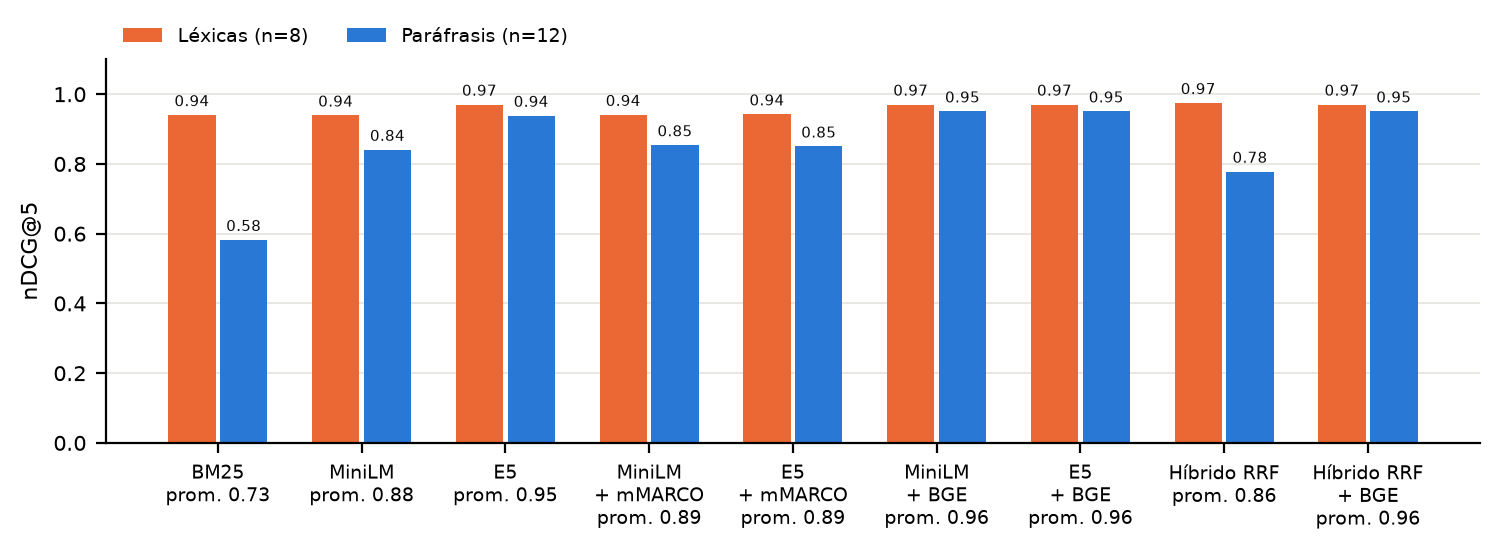

In [20]:
# Figura del reporte: nDCG@5 por configuración, separado por tipo de consulta.
COLOR_TIPO = {"léxica": "#eb6834", "paráfrasis": "#2a78d6"}
fig, ax = plt.subplots(figsize=(7.6, 2.9), dpi=200)
x = np.arange(len(ORDEN_CONFIG))
ancho = 0.36
for desplazamiento, tipo in ((-ancho / 2, "léxica"), (ancho / 2, "paráfrasis")):
    valores = por_tipo[tipo].values
    n_tipo = sum(c.tipo == tipo for c in CONSULTAS)
    ax.bar(x + desplazamiento, valores, ancho - 0.03, color=COLOR_TIPO[tipo],
           label=f"{tipo.capitalize()}s (n={n_tipo})" if tipo == "léxica" else f"Paráfrasis (n={n_tipo})")
    for xi, v in zip(x + desplazamiento, valores):
        ax.text(xi, v + 0.015, f"{v:.2f}", ha="center", va="bottom", fontsize=5.5, color="#0b0b0b")
# El promedio de las 20 consultas va en la etiqueta del eje para no encimarse con los valores de las barras.
ax.set_xticks(x, [f"{c.replace(' + ', chr(10) + '+ ')}\nprom. {v:.2f}" for c, v in zip(ORDEN_CONFIG, agregado["nDCG@5"])],
              fontsize=6.8)
ax.set_ylabel("nDCG@5", fontsize=8)
ax.set_ylim(0, 1.1)
ax.tick_params(axis="y", labelsize=7.5)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.grid(axis="y", color="#e4e3df", linewidth=0.6)
ax.set_axisbelow(True)
ax.legend(fontsize=7, frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(0, 1.13))
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "ndcg_por_configuracion.png", bbox_inches="tight")
plt.show()

## 6. Paso 5 — Interfaz gráfica: tablero comparativo lado a lado

Interfaz con `ipywidgets` con los tres elementos que pide la actividad:

1. **Barra de búsqueda** para escribir la consulta en lenguaje natural.
2. **Botón de ejecución** («Buscar»). Presionar Enter en la barra hace lo mismo.
3. **Área de salida con el tablero lado a lado**: **a la izquierda, el Top 5 del buscador semántico con
   su puntaje de similitud coseno**; **a la derecha, el Top 5 del buscador léxico BM25 de la unidad 2**
   con su puntuación BM25.

Controles adicionales, opcionales: un menú con las 20 consultas de evaluación, el modelo de
*embeddings* (MiniLM o E5) y un selector de *re-ranking*. Este viene apagado por defecto. Si se activa,
la columna semántica se ordena con el *cross-encoder* (paso 3) y conserva a la vista la similitud coseno
de cada documento. Si la consulta pertenece al conjunto de evaluación, cada tarjeta muestra además su
grado de relevancia y cada columna su nDCG@5. Bajo cada encabezado aparece la latencia de esa búsqueda.

In [21]:
TOP_TABLERO = 5
SIN_RERANKING = "Sin re-ranking"

CSS_TABLERO = """
<style>
.tb-root{font-family:system-ui,-apple-system,sans-serif;line-height:1.4;color:#0b0b0b}
.tb-head{margin:0 0 8px;font-size:13px;color:#52514e}
.tb-grid{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:12px}
.tb-col{background:#fcfcfb;border:1px solid #e4e3df;border-radius:10px;padding:8px 12px}
.tb-col h4{margin:0 0 2px;font-size:14px}
.tb-meta{font-size:11.5px;color:#52514e;margin-bottom:6px}
.tb-card{border-top:1px solid #ecebe7;padding:6px 0}
.tb-card b{font-size:12.5px}
.tb-sub{font-size:11px;color:#52514e}
.tb-score{float:right;background:#eaf2fc;color:#0b3d7a;border-radius:10px;padding:0 8px;font-size:11px;
          font-weight:600;font-variant-numeric:tabular-nums}
.tb-rel2{background:#d9f2e6;color:#0b5a3c;border-radius:6px;padding:0 6px;font-size:10.5px;font-weight:600}
.tb-rel1{background:#fff1cc;color:#6b4a00;border-radius:6px;padding:0 6px;font-size:10.5px;font-weight:600}
.tb-rel0{background:#f1f0ec;color:#52514e;border-radius:6px;padding:0 6px;font-size:10.5px}
.tb-vacio{font-size:12px;color:#a33;padding:8px 0}
</style>
"""


def _etiqueta_relevancia(doc_id: str, qrels: dict[str, int] | None) -> str:
    """Insignia de grado de relevancia (texto + color, nunca solo color)."""
    if qrels is None:
        return ""
    grado = qrels.get(doc_id, 0)
    texto = {2: "✓✓ muy relevante", 1: "✓ parcial", 0: "· no relevante"}[grado]
    return f" <span class='tb-rel{grado}'>{texto}</span>"


def _columna_html(titulo: str, resultados: list[dict], puntaje: Callable[[dict], str], detalle: Callable[[dict, int], str],
                  ms: float, qrels: dict[str, int] | None) -> str:
    """Compone una columna del tablero con el Top-``TOP_TABLERO``.

    Args:
        titulo: Encabezado de la columna.
        resultados: Ranking completo del sistema.
        puntaje: Texto del puntaje principal de cada resultado (insignia a la derecha).
        detalle: Texto adicional bajo el título de cada resultado, dada su posición.
        ms: Latencia medida de la búsqueda.
        qrels: Juicios de la consulta, o ``None`` si no pertenece al conjunto de evaluación.
    """
    top = resultados[:TOP_TABLERO]
    metrica = f" · nDCG@5 = <b>{ndcg_at([r['id'] for r in top], qrels):.2f}</b>" if qrels else ""
    latencia = f"{ms:.1f} ms" if ms >= 1 else f"{ms:.2f} ms"
    partes = [f"<div class='tb-col'><h4>{titulo}</h4><div class='tb-meta'>{latencia}{metrica}</div>"]
    if not top:
        partes.append("<div class='tb-vacio'>Sin resultados: ningún término de la consulta está en el índice.</div>")
    for pos, r in enumerate(top, start=1):
        doc = DOCS[r["id"]]
        partes.append(
            f"<div class='tb-card'><span class='tb-score'>{puntaje(r)}</span>"
            f"<b>{pos}. {_html.escape(doc['titulo'])}</b>{_etiqueta_relevancia(r['id'], qrels)}"
            f"<div class='tb-sub'>{doc['id']} · {_html.escape(doc['categoria'])}{detalle(r, pos)}</div></div>"
        )
    partes.append("</div>")
    return "".join(partes)


def _movimiento(r: dict, pos: int) -> str:
    """Posición previa al re-ranking y dirección del cambio."""
    if "rank_inicial" not in r:
        return ""
    delta = r["rank_inicial"] - pos
    flecha = "↑" * min(delta, 3) if delta > 0 else "↓" if delta < 0 else "="
    return f" · CE {r['score_ce']:.3g} · por coseno era #{r['rank_inicial']} {flecha}"


def tablero_html(consulta: str, modelo: str = "E5", reranker: str = SIN_RERANKING) -> str:
    """Ejecuta la consulta en ambos buscadores y devuelve el tablero lado a lado en HTML.

    Izquierda: Top 5 semántico con su similitud coseno. Derecha: Top 5 de BM25 con su puntuación.

    Args:
        consulta: Consulta en lenguaje natural.
        modelo: Modelo de *embeddings* del buscador semántico.
        reranker: ``SIN_RERANKING`` (por defecto) o la clave de un *cross-encoder* para ordenar la columna
            semántica con el pipeline de dos etapas.

    Returns:
        HTML autocontenido (con estilos) listo para ``display(HTML(...))``.
    """
    qrels = QRELS.get(consulta)
    tiempos: dict[str, float] = {}
    semantico = buscar_semantico(consulta, modelo, K_CANDIDATOS, tiempos)
    ms_semantico = (tiempos["codificar"] + tiempos["indice"]) * 1000
    titulo_sem = f"Buscador semántico · {modelo}"
    if reranker != SIN_RERANKING:
        semantico = reranquear(consulta, semantico, reranker, tiempos)
        ms_semantico += tiempos["reranking"] * 1000
        titulo_sem += f" + re-ranking {reranker}"
    t0 = time.perf_counter()
    lexico = bm25.buscar(consulta, K_CANDIDATOS)
    ms_bm25 = (time.perf_counter() - t0) * 1000

    terminos = preprocesar(consulta)
    desconocidos = [t for t in terminos if bm25.df(t) == 0]
    aviso = f" · <b>términos fuera del vocabulario de BM25:</b> {', '.join(desconocidos)}" if desconocidos else ""
    encabezado = (
        f"<div class='tb-head'>Consulta: <b>«{_html.escape(consulta)}»</b> · raíces BM25: "
        f"<code>{_html.escape(' '.join(terminos)) or '—'}</code>{aviso}"
        + (" · <i>consulta del conjunto de evaluación: se muestran los juicios</i>" if qrels else "")
        + "</div>"
    )
    columnas = (
        _columna_html(titulo_sem, semantico, lambda r: f"similitud {r['score']:.3f}", _movimiento, ms_semantico, qrels)
        + _columna_html("Buscador léxico · BM25 (unidad 2)", lexico, lambda r: f"BM25 {r['score']:.2f}",
                        lambda r, pos: "", ms_bm25, qrels)
    )
    return f"{CSS_TABLERO}<div class='tb-root'>{encabezado}<div class='tb-grid'>{columnas}</div></div>"


def construir_interfaz() -> "widgets.Widget":
    """Interfaz del paso 5: barra de búsqueda, botón de ejecución y tablero lado a lado."""
    barra = widgets.Text(value=CONSULTAS[9].texto, placeholder="Escribe tu consulta en lenguaje natural…",
                         description="Consulta:", continuous_update=False,
                         layout=widgets.Layout(width="70%"), style={"description_width": "70px"})
    boton = widgets.Button(description="Buscar", button_style="primary", icon="search",
                           tooltip="Ejecutar la búsqueda en ambos buscadores")
    ejemplos = widgets.Dropdown(
        options=[("— consultas de evaluación (opcional) —", "")] + [(f"{c.id} · {c.tipo} · {c.texto}", c.texto) for c in CONSULTAS],
        description="Ejemplos:", layout=widgets.Layout(width="70%"), style={"description_width": "70px"})
    modelo = widgets.ToggleButtons(options=list(DENSOS), value="E5", description="Embeddings:",
                                   style={"description_width": "80px", "button_width": "80px"})
    reranking = widgets.Dropdown(options=[SIN_RERANKING] + list(RERANKERS), value=SIN_RERANKING,
                                 description="Re-ranking:", style={"description_width": "80px"},
                                 layout=widgets.Layout(width="260px"))
    salida = widgets.Output()

    def ejecutar(*_) -> None:
        """Lanza la búsqueda con los valores actuales y redibuja el tablero."""
        with salida:
            salida.clear_output(wait=True)
            consulta = barra.value.strip()
            if not consulta:
                display(HTML("<i>Escribe una consulta para comenzar.</i>"))
                return
            display(HTML(tablero_html(consulta, modelo.value, reranking.value)))

    def usar_ejemplo(cambio: dict) -> None:
        """Copia la consulta elegida a la barra y ejecuta la búsqueda."""
        if cambio["new"]:
            barra.value = cambio["new"]
            ejecutar()

    boton.on_click(ejecutar)
    barra.observe(lambda _: ejecutar(), names="value")  # Enter en la barra equivale al botón
    ejemplos.observe(usar_ejemplo, names="value")
    modelo.observe(lambda _: ejecutar(), names="value")
    reranking.observe(lambda _: ejecutar(), names="value")
    titulo = widgets.HTML(
        "<h3 style='margin:0 0 4px'>🔎 Buscador semántico vs. buscador léxico</h3>"
        f"<div style='color:#52514e'>{len(CORPUS)} documentos · izquierda: Top {TOP_TABLERO} semántico "
        f"(similitud coseno, índice HNSW) · derecha: Top {TOP_TABLERO} BM25 (k1=1.5, b=0.75)</div>"
    )
    ejecutar()
    return widgets.VBox([titulo, widgets.HBox([barra, boton]), ejemplos,
                         widgets.HBox([modelo, reranking]), salida])


if HAY_WIDGETS:
    display(construir_interfaz())
else:
    print("ipywidgets no disponible: usa display(HTML(tablero_html('tu consulta'))) en la celda siguiente.")

> **Nota para la revisión.** La salida de un *widget* solo se dibuja con un kernel activo. Para que el
> tablero quede visible en el `.ipynb` entregado, las celdas siguientes lo renderizan de forma estática
> con el mismo código (`tablero_html()`): dos consultas con la configuración por defecto y una con el
> *re-ranking* activado.

In [22]:
display(HTML(tablero_html("cita con el doctor por videollamada")))

In [23]:
display(HTML(tablero_html("pan apto para celíacos")))

In [24]:
# Misma interfaz con el pipeline de dos etapas: la columna semántica la ordena el cross-encoder BGE.
display(HTML(tablero_html("vehículo de cero emisiones", "E5", "BGE")))

## 7. Paso 6 — Casos en los que el semántico recuperó lo que BM25 ignoró por completo

Criterio estricto de "ignoró por completo": un documento relevante que **no recibe ninguna puntuación de
BM25** —ni un solo término de la consulta aparece en él, así que no está en la lista de candidatos de BM25 a
ninguna profundidad— y que el mejor pipeline semántico, **E5 + BGE**, sí coloca en su Top-5. La celda los detecta
automáticamente sobre las 20 consultas, junto con el término que provocó el fallo léxico.

In [25]:
filas = []
for c in CONSULTAS:
    vistos_bm25 = set(bm25.puntuar(c.texto))
    top5_sem = RANKINGS["E5 + BGE"][c.texto][:5]
    for pos, doc_id in enumerate(top5_sem, start=1):
        if c.qrels.get(doc_id, 0) > 0 and doc_id not in vistos_bm25:
            filas.append({
                "consulta": c.id, "tipo": c.tipo, "texto": c.texto,
                "documento": f"{doc_id} · {DOCS[doc_id]['titulo']}", "grado": c.qrels[doc_id],
                "posición E5+BGE": pos,
                "raíces de la consulta (df)": " ".join(f"{t}={bm25.df(t)}" for t in preprocesar(c.texto)),
            })
ignorados = pd.DataFrame(filas)
ignorados.to_csv(DIR_RESULTADOS / "ejemplos_semantico_vs_lexico.csv", index=False)
print(f"{len(ignorados)} documentos relevantes invisibles para BM25 y recuperados en el Top-5 semántico, "
      f"en {ignorados['consulta'].nunique()} de {len(CONSULTAS)} consultas:\n")
print(ignorados.drop(columns="texto").to_string(index=False))

12 documentos relevantes invisibles para BM25 y recuperados en el Top-5 semántico, en 9 de 20 consultas:

consulta       tipo                                     documento  grado  posición E5+BGE         raíces de la consulta (df)
     q07     léxica       doc_028 · Actividad física y longevidad      1                3          prepar=1 corr=1 maraton=1
     q10 paráfrasis doc_027 · Telemedicina y consulta a distancia      2                1         cit=2 doctor=0 videollam=0
     q11 paráfrasis          doc_001 · Redes neuronales profundas      1                3  orden=2 aprend=3 part=17 ejempl=1
     q12 paráfrasis  doc_090 · Automóviles eléctricos y autonomía      2                1          vehicul=4 cer=1 emision=3
     q13 paráfrasis              doc_107 · Gestión de contraseñas      2                3    evit=5 rob=2 cuent=0 internet=0
     q14 paráfrasis   doc_056 · Bancos centrales y tipo de cambio      1                2                sub=5 preci=1 cos=0
     q14 paráfrasis

In [26]:
def explicar_caso(consulta: str) -> None:
    """Imprime por qué BM25 falla y qué hace el pipeline semántico con la misma consulta."""
    c = next(x for x in CONSULTAS if x.texto == consulta)
    print(f"«{consulta}»  ({c.id}, relevantes: {c.qrels})")
    print(f"  raíces BM25 y su df: {[(t, bm25.df(t)) for t in preprocesar(consulta)]}")
    for nombre in ("BM25", "E5", "E5 + mMARCO", "E5 + BGE"):
        top = RANKINGS[nombre][consulta][:5]
        marcas = " ".join(f"{d}[{c.qrels.get(d, 0)}]" for d in top) or "— sin resultados —"
        print(f"  {nombre:11} nDCG@5={ndcg_at(top, c.qrels):.2f} -> {marcas}")
    print()


for consulta in ("cita con el doctor por videollamada", "por qué sube el precio de las cosas",
                 "pan apto para celíacos", "el derrumbe del imperio de Roma"):
    explicar_caso(consulta)

«cita con el doctor por videollamada»  (q10, relevantes: {'doc_027': 2})
  raíces BM25 y su df: [('cit', 2), ('doctor', 0), ('videollam', 0)]
  BM25        nDCG@5=0.00 -> doc_046[0] doc_003[0]
  E5          nDCG@5=1.00 -> doc_027[2] doc_006[0] doc_020[0] doc_047[0] doc_023[0]
  E5 + mMARCO nDCG@5=1.00 -> doc_027[2] doc_006[0] doc_109[0] doc_023[0] doc_020[0]
  E5 + BGE    nDCG@5=1.00 -> doc_027[2] doc_023[0] doc_020[0] doc_026[0] doc_003[0]

«por qué sube el precio de las cosas»  (q14, relevantes: {'doc_050': 2, 'doc_052': 1, 'doc_053': 1, 'doc_056': 1})
  raíces BM25 y su df: [('sub', 5), ('preci', 1), ('cos', 0)]
  BM25        nDCG@5=0.66 -> doc_050[2] doc_117[0] doc_067[0] doc_043[0] doc_057[0]
  E5          nDCG@5=0.91 -> doc_050[2] doc_053[1] doc_056[1] doc_095[0] doc_015[0]
  E5 + mMARCO nDCG@5=0.89 -> doc_050[2] doc_056[1] doc_095[0] doc_053[1] doc_116[0]
  E5 + BGE    nDCG@5=0.99 -> doc_050[2] doc_056[1] doc_053[1] doc_095[0] doc_052[1]

«pan apto para celíacos»  (q15, relevant

### 7.1 También hay que mirar dónde pierde el semántico

Un análisis honesto incluye los casos inversos: consultas en las que BM25 supera al mejor pipeline
semántico, y consultas en las que el *re-ranking* empeora el orden que ya traía el coseno.

In [27]:
TEXTO_CONSULTA = {c.id: c.texto for c in CONSULTAS}
pierde = pivote[pivote["BM25"] > pivote["E5 + BGE"] + 1e-9][["BM25", "E5", "E5 + BGE"]].round(2)
pierde.insert(0, "consulta", [TEXTO_CONSULTA[i] for i in pierde.index])
print("Consultas en las que BM25 obtiene mayor nDCG@5 que E5 + BGE:\n")
print(pierde.to_string() if len(pierde) else "  ninguna")
print()
for i in pierde.index:
    explicar_caso(TEXTO_CONSULTA[i])

Consultas en las que BM25 obtiene mayor nDCG@5 que E5 + BGE:

  ninguna



In [28]:
# ¿Cuándo empeora el re-ranking? Consultas en las que el cross-encoder baja el nDCG@5 del coseno de E5.
for clave_rr in RERANKERS:
    peor = pivote[pivote[f"E5 + {clave_rr}"] < pivote["E5"] - 1e-9]
    print(f"E5 + {clave_rr} empeora a E5 en {len(peor)} consultas: "
          + ", ".join(f"{i} ({pivote.loc[i, 'E5']:.2f}->{pivote.loc[i, f'E5 + {clave_rr}']:.2f})" for i in peor.index))
print()
explicar_caso("planetas parecidos a la Tierra donde podría haber vida")
explicar_caso("cómo evitar que me roben las cuentas en internet")

E5 + mMARCO empeora a E5 en 12 consultas: q01 (0.99->0.91), q05 (0.98->0.88), q07 (1.00->0.94), q09 (0.96->0.94), q11 (1.00->0.88), q13 (0.83->0.72), q14 (0.91->0.89), q15 (1.00->0.96), q16 (1.00->0.83), q17 (0.96->0.63), q19 (0.93->0.83), q20 (0.94->0.80)
E5 + BGE empeora a E5 en 4 consultas: q04 (0.98->0.97), q07 (1.00->0.96), q13 (0.83->0.66), q20 (0.94->0.80)

«planetas parecidos a la Tierra donde podría haber vida»  (q17, relevantes: {'doc_013': 2, 'doc_012': 1})
  raíces BM25 y su df: [('planet', 7), ('parec', 2), ('tierr', 3), ('podr', 1), ('vid', 3)]
  BM25        nDCG@5=0.83 -> doc_013[2] doc_115[0] doc_106[0] doc_024[0] doc_008[0]
  E5          nDCG@5=0.96 -> doc_013[2] doc_018[0] doc_012[1] doc_010[0] doc_014[0]
  E5 + mMARCO nDCG@5=0.63 -> doc_012[1] doc_111[0] doc_112[0] doc_013[2] doc_115[0]
  E5 + BGE    nDCG@5=1.00 -> doc_013[2] doc_012[1] doc_115[0] doc_112[0] doc_017[0]

«cómo evitar que me roben las cuentas en internet»  (q13, relevantes: {'doc_102': 2, 'doc_107': 2,

## 8. Conclusiones

1. **El salto lo da la representación densa, no el *re-ranking*.** Pasar de BM25 a E5 sube el nDCG@5
   de **0.725 a 0.951** y el MRR de 0.875 a 1.000. Casi todo el avance está en las consultas de
   paráfrasis (**0.582 → 0.938**), mientras que en las léxicas BM25 ya era bueno (0.940 → 0.970). E5
   supera o empata a BM25 en 18 de 20 consultas. Con criterio estricto, el pipeline semántico recuperó
   en su Top-5 **12 documentos relevantes que BM25 no puntuó en absoluto**, en 9 consultas (*doctor*,
   *celíacos*, *cuidar el corazón*, *por qué sube el precio de las cosas*…).

2. **El modelo de *embeddings* importa más que su dimensión.** E5 (768 d, entrenado para recuperar
   pasajes) supera a MiniLM (384 d, entrenado con paráfrasis) en nDCG@5 (0.951 vs. 0.880) y en
   paráfrasis (0.938 vs. 0.841). A cambio cuesta ~2.3× más al codificar cada consulta (≈20 ms vs. ≈9 ms
   en CPU). E5 concentra los cosenos en una banda estrecha (0.69–0.89), así que sus puntuaciones
   absolutas no sirven como umbral: solo el orden es interpretable.

3. **Un *re-ranker* débil empeora lo que ya funcionaba.** El *cross-encoder* ligero mMARCO **bajó** a E5
   de 0.951 a 0.887 (empeora 12 consultas y mejora 2). El grande BGE-reranker-v2-m3 lo sube a
   **0.959** (mejora 8, empata 8 y empeora 4) y corrige casos como *vehículo de cero emisiones*
   (0.72 → 1.00). El *re-ranking* no es una mejora automática: su valor depende de que el
   *cross-encoder* sea mejor juez que el *bi-encoder* que lo alimenta.

4. **La latencia es el precio de la segunda etapa.** Con 20 candidatos en CPU, mMARCO añade ≈170 ms
   (~10× sobre E5 solo) y BGE ≈1.7 s (~80×). BM25 responde en ≈0.1 ms y el coseno con HNSW en menos de
   0.2 ms: en una búsqueda densa el costo dominante es codificar la consulta, no buscar en el índice.
   La primera etapa ya entrega casi todo lo relevante (recall@20 = 0.975: solo un documento de grado 1
   de q03 queda fuera, en todos los sistemas), así que con BGE el orden final lo decide el
   *cross-encoder*: MiniLM + BGE, E5 + BGE e Híbrido + BGE obtienen el mismo nDCG@5 en las 20 consultas.
   En este corpus, el *bi-encoder* barato basta como primera etapa si después hay un buen *re-ranker*.

5. **La fusión híbrida sin *re-ranking* no ayudó en este corpus.** RRF(BM25, E5) es la mejor opción en
   consultas léxicas (0.975), pero en paráfrasis cae a 0.778, porque BM25 inyecta coincidencias
   espurias (en *cita con el doctor*, la palabra *cita* recupera un documento de tenis). Con BGE detrás,
   el híbrido iguala a E5 + BGE (0.959). Su valor real aparecería con nombres propios, siglas o
   códigos raros, que este corpus apenas contiene.

6. **Recomendación.** Si una latencia de 1–2 s es aceptable (por ejemplo, la etapa de recuperación de un
   RAG), conviene **E5 + BGE-reranker**. Para búsqueda interactiva conviene **E5 solo** (0.951 en ≈20 ms),
   que obtiene el 99 % de la calidad con ~1 % del tiempo. **Limitaciones:** 20 consultas y 120
   documentos; los juicios de relevancia los asignó una sola persona; BGE se eligió después de ver los
   resultados de mMARCO; y todas las latencias se midieron en CPU, donde los tiempos absolutos varían
   hasta ~50 % entre ejecuciones según la carga de la máquina (las proporciones se mantienen). Con GPU el costo del *re-ranking* se
   reduciría en uno o dos órdenes de magnitud.

---

### Cómo reproducir este notebook

```bash
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
jupyter lab Actividad4A_Buscador_Semantico.ipynb     # Kernel -> Restart & Run All
```